# Annual Longshore Sediment Transport

Jupyter notebook version of the *"annual longshore transport"* pdf sheet of the `Littoral.xls` workbook.
The year is schematised into a set of offshore wave cases (wave height, period, direction, number of days).
For every case the waves are propagated from deep water to the breaker line, the wave-driven longshore current
is computed, and the longshore transport is evaluated with four formulae:

| Method | Reference |
|---|---|
| Kamphuis (original) | Kamphuis 1991 |
| Kamphuis (modified) | Kamphuis 2013 |
| CERC | CERC formula |
| Van Rijn | Van Rijn 2014 (includes tidal currents and swell correction) |

The annual net and gross transport are then obtained by summing over all cases.

**Sign convention** (as in the sheet): angles are measured with respect to North (direction of wave propagation).
The wave angle relative to the shore normal is positive when the wave angle to North is larger than the shore-normal angle.
A clockwise longshore current is positive, an anti-clockwise one is negative.


## 1. Imports

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

figures = {}
tables = {}

In [26]:
SAVE = False   # True = save figures and tables in results/ (overwrites the files there)

fig_dir = ("../results")
table_dir = ("../results")

## 2. Input values

Global inputs (red cells at the top of the sheet). Values below are those of the PDF printout.

In [16]:
# Global input parameters 
rho_s        = 2650   # Sediment density                          (kg/m3)
rho_bulk     = 1600   # Bulk density of sand bed                  (kg/m3)
mud_pct      = 20     # Percentage of mud in bed, 0-20 %          (%)
swell_pct    = 0.4    # Percentage of offshore swell (H>1m,T>10s), 0-40 %  [value as printed in the PDF]
u_tide_pos   = 0.3    # Positive tidal current velocity (50 % of time)  (m/s) - south-going
u_tide_neg   = -0.3   # Negative tidal current velocity (50 % of time)  (m/s) - north-going
calib        = 1.0    # Calibration factor (default = 1)

# Constants used in the sheet
PI_A = 3.141    # used in cos() of breaker depth and in sin(2*theta)
PI_B = 3.1416   # used in the asin() for the breaker angle

### Wave cases

One row per case (case 1 … 49 as in the sheet). Only the cases with a non-zero number of days matter; unused cases keep
the sheet defaults (0 days, `Hs = T = 1e-8`, shore normal 135°) so that the table has the same shape as in the spreadsheet.
Cases 1, 2, 3 and 12 are the populated ones (365 days in total).

In [17]:
N_CASES = 49

cases = pd.DataFrame({
    "case":       np.arange(1, N_CASES + 1),
    "h0":         30.0,       # offshore water depth                (m)
    "d50":        0.00008,    # sediment size                       (m)
    "tanb":       0.002,      # slope of surf zone                  (-)
    "gamma":      0.6,        # breaker coefficient                 (-)
    "days":       0.0,        # number of days                      (days)
    "Hs0":        1e-8,       # offshore significant wave height   (m)
    "T":          1e-8,       # wave period                         (s)
    "wave_dir":   0.0,        # wave angle to North                 (deg)
    "shore_norm": 135.0,      # shore-normal angle to North         (deg)
}).set_index("case")

# populated cases:  days, Hs0, T, wave angle to N, shore-normal angle to N
populated = {
    1:  (151, 0.90, 5.7, 262, 340),
    2:  (0,   0.64, 4.2,  48, 340),
    3:  (92,  0.54, 4.9, 320, 340),
    12: (122, 0.64, 4.2,  48, 340),
}
for c, (days, Hs, T, ang, sn) in populated.items():
    cases.loc[c, ["days", "Hs0", "T", "wave_dir", "shore_norm"]] = [days, Hs, T, ang, sn]

total_days = cases["days"].sum()
print(f"Total number of days: {total_days:.0f}  (should be 365)")
assert abs(total_days - 365) < 1e-9
cases[cases.index.isin(populated)]

Total number of days: 365  (should be 365)


,h0,d50,tanb,gamma,days,Hs0,T,wave_dir,shore_norm
case,,,,,,,,,
1,30.0000,0.0001,0.0020,0.6000,151.0000,0.9000,5.7000,262.0000,340.0000
2,30.0000,0.0001,0.0020,0.6000,0.0000,0.6400,4.2000,48.0000,340.0000
3,30.0000,0.0001,0.0020,0.6000,92.0000,0.5400,4.9000,320.0000,340.0000
12,30.0000,0.0001,0.0020,0.6000,122.0000,0.6400,4.2000,48.0000,340.0000


## 3. Wave angle relative to the shore normal

$$\alpha_0 = \text{wave angle to N} - \text{shore normal angle to N}$$

Angles whose absolute value is larger than ~90° (waves travelling offshore) are set to 180°, which switches off the transport
for that case (breaker depth is set to 0).

In [18]:
def wave_angle_to_shore_normal(wave_dir, shore_norm):
    L = wave_dir - shore_norm                                    # col L
    M = np.where(L >= 89, np.where(L <= 271, 180, -360 + L), L)  # col M
    N = np.where(M <= -89, np.where(M >= -271, 180, 360 + M), M) # col N
    return L, M, N

cases["L"], cases["M"], cases["alpha0"] = wave_angle_to_shore_normal(cases["wave_dir"].values,
                                                                      cases["shore_norm"].values)
cases.loc[cases.days > 0, ["wave_dir", "shore_norm", "L", "M", "alpha0"]]

,wave_dir,shore_norm,L,M,alpha0
case,,,,,
1,262.0000,340.0000,-78.0000,-78.0000,-78.0000
3,320.0000,340.0000,-20.0000,-20.0000,-20.0000
12,48.0000,340.0000,-292.0000,-292.0000,68.0000


## 4. Wave transformation to the breaker line

**Wavelength** (explicit approximation of the dispersion relation, with $x = 4.02\,h/T^2$):

$$L = \frac{2\pi h}{\sqrt{x^2 + \dfrac{x}{1 + 0.666x + 0.355x^2 + 0.161x^3 + 0.0632x^4 + 0.0218x^5 + 0.00654x^6}}}$$

(the sheet uses $2\pi \approx 6.28$)

* offshore wavelength $L_0$ (using $h_0$) and celerity $c_0 = L_0/T$
* breaker depth $h_{br} = \left(\dfrac{H_{s,0}^2\, c_0 \cos\alpha_0}{1.8\cdot 3.13\cdot\gamma^2}\right)^{0.4}$ (only if $\alpha_0 \le 90^\circ$)
* breaker height $H_{s,br} = \gamma\, h_{br}$
* wavelength at the breaker line $L_{br}$ (same formula with $h = h_{br}$)
* breaker angle (Snell): $\alpha_{br} = \arcsin\!\left(\dfrac{L_{br}}{L_0}\sin\alpha_0\right)$

In [19]:
def wavelength(h, T):
    """Explicit dispersion approximation used in the workbook."""
    x = 4.02 * h / T**2
    poly = 1 + 0.666*x + 0.355*x**2 + 0.161*x**3 + 0.0632*x**4 + 0.0218*x**5 + 0.00654*x**6
    return 6.28 * h / np.sqrt(x**2 + x / poly)

h0, T, Hs0, gam = (cases[k].values for k in ("h0", "T", "Hs0", "gamma"))
alpha0 = cases["alpha0"].values

L0 = wavelength(h0, T)                                                  # col P
c0 = L0 / T                                                             # col Q

# breaker depth (col R) - zero for waves travelling away from the coast
with np.errstate(invalid="ignore"):
    hbr = np.where(alpha0 <= 90,
                   (Hs0**2 * c0 * np.cos(alpha0/180*PI_A) / 1.8 / 3.13 / gam**2) ** 0.4,
                   0.0)
Hsbr = gam * hbr                                                        # col S
Lbr  = np.where(hbr > 0, wavelength(np.where(hbr > 0, hbr, 1.0), T), 0.0)   # col T
alphabr = np.degrees(np.arcsin(Lbr / L0 * np.sin(alpha0/180*PI_B)))     # col U  (Snell's law)
sin2a   = np.sin(2 * alphabr/180 * PI_A)                                # col V

cases["L0"], cases["c0"] = L0, c0
cases["hbr"], cases["Hsbr"], cases["Lbr"] = hbr, Hsbr, Lbr
cases["alpha_br"], cases["sin2a"] = alphabr, sin2a

cases.loc[cases.days.gt(0) | cases.index.isin([2]), ["L0","c0","hbr","Hsbr","Lbr","alpha_br","sin2a"]]

,L0,c0,hbr,Hsbr,Lbr,alpha_br,sin2a
case,,,,,,,
1,50.6439,8.8849,0.8859,0.5315,16.4957,-18.5784,-0.6039
2,27.5553,6.5608,0.7558,0.4535,11.1070,21.9458,0.6932
3,37.4932,7.6517,1.0134,0.6080,15.0113,-7.8706,-0.2712
12,27.5553,6.5608,0.7558,0.4535,11.1070,21.9458,0.6932


## 5. Longshore current

* wave-driven longshore current: $V_L = 0.3 \cdot 3.13 \cdot \sqrt{H_{s,br}} \cdot \sin 2\alpha_{br}$
* effective current (Van Rijn only): $V_{eff} = V_L + 0.5\,(u_{tide,+} + u_{tide,-})$
* swell factor: $K_{swell} = (1 - p_{swell}/100)\cdot 1 + (p_{swell}/100)\cdot 1.5$

In [20]:
VL   = 0.3 * 3.13 * np.sqrt(Hsbr) * sin2a                        # col W
Veff = VL + 0.5 * (u_tide_pos + u_tide_neg)                      # col X
Kswell = (1 - swell_pct/100) * 1 + (swell_pct/100) * 1.5         # col Y

cases["VL"], cases["Veff"], cases["Kswell"] = VL, Veff, Kswell
cases.loc[cases.days.gt(0), ["VL", "Veff", "Kswell"]]

,VL,Veff,Kswell
case,,,
1,-0.4134,-0.4134,1.0020
3,-0.1986,-0.1986,1.0020
12,0.4383,0.4383,1.0020


## 6. Longshore transport per case

All formulas give volumes in m³ per case (i.e. over `days` days, **including pores**). Common factors:

* `f_mud = 1 - mud_pct/100`
* `secs = days · 24 · 3600`

| Method | Formula |
|---|---|
| Kamphuis 1991 | $\pm 3.8\,c\,f_{mud}\,\dfrac{\text{secs}}{\rho_{bulk}}\,T^{1.5}\,d_{50}^{-0.25}\,\tan\beta^{0.75}\,H_{s,br}^{2}\,|\sin 2\alpha_{br}|^{0.6}$ |
| Kamphuis 2013 | $\pm 0.24\,c\,f_{mud}\,\dfrac{\text{secs}}{\rho_{bulk}}\,T^{0.89}\,d_{50}^{-0.69}\,\tan\beta^{0.86}\,H_{s,br}^{2.75}\,|\sin 2\alpha_{br}|^{0.5}$ |
| CERC | $c\,f_{mud}\,0.023\cdot 3.13\,\dfrac{\text{secs}}{\rho_{bulk}}\,\gamma^{-0.5}\,H_{s,br}^{2.5}\,\sin 2\alpha_{br}\;\rho_{bulk}$ |
| Van Rijn 2014 | $c\,f_{mud}\,0.0006\,\rho_s\,\dfrac{\text{secs}}{\rho_{bulk}}\,K_{swell}\,d_{50}^{-0.6}\,\tan\beta^{0.4}\,H_{s,br}^{2.6}\,V_{eff}$ |

The sign of the Kamphuis results follows the sign of the wave angle to the shore normal ($\alpha_0$).

In [21]:
f_mud = 1 - mud_pct / 100
secs  = cases["days"].values * 24 * 3600
d50, tanb = cases["d50"].values, cases["tanb"].values
sgn = np.where(alpha0 > 0, 1.0, -1.0)

# Kamphuis 1991
Q_k91 = sgn * 3.8 * calib * f_mud * secs / rho_bulk * T**1.5 * d50**(-0.25) * tanb**0.75 * Hsbr**2 * np.abs(sin2a)**0.6
# Kamphuis 2013
Q_k13 = sgn * 0.24 * calib * f_mud * secs / rho_bulk * T**0.89 * d50**(-0.69) * tanb**0.86 * Hsbr**2.75 * np.abs(sin2a)**0.5
# CERC
Q_cerc = calib * f_mud * 0.023 * 3.13 * secs / rho_bulk * gam**(-0.5) * Hsbr**2.5 * sin2a * rho_bulk
# Van Rijn 2014
Q_vr = calib * f_mud * 0.0006 * rho_s * secs / rho_bulk * Kswell * d50**(-0.6) * tanb**0.4 * Hsbr**2.6 * Veff

Q = pd.DataFrame({
    "Kamphuis 1991": Q_k91,
    "Kamphuis 2013": Q_k13,
    "CERC":          Q_cerc,
    "Van Rijn 2014": Q_vr,
}, index=cases.index)
Q.index.name = "case"
Q[cases.days.gt(0) | (cases.index == 2)]

,Kamphuis 1991,Kamphuis 2013,CERC,Van Rijn 2014
case,,,,
1,"-7,041.6677","-3,227.1308","-120,654.1500","-19,862.1425"
2,0.0000,0.0000,0.0000,0.0000
3,"-2,768.2324","-1,667.1246","-46,210.8608","-8,246.4606"
12,"2,845.2871","1,375.4900","75,232.3558","11,259.2763"


## 7. Annual totals

* **NET** = sum of the signed transports
* **Gross** = sum of the absolute transports
* **Value 1** = (NET − Gross) / 2 → transport in the negative direction
* **Value 2** = (NET + Gross) / 2 → transport in the positive direction

> Note: in the sheet the Van Rijn totals sum rows of cases 1-48 only (case 49 excluded); case 49 carries 0 days so this does not change the result.

In [22]:
net   = Q.sum()
gross = Q.abs().sum()
summary = pd.DataFrame({
    "NET":     net,
    "Gross":   gross,
    "Value 1 (negative dir.)": (net - gross) / 2,
    "Value 2 (positive dir.)": (net + gross) / 2,
}).T
summary.style.format("{:,.2f}")

,Kamphuis 1991,Kamphuis 2013,CERC,Van Rijn 2014
NET,"-6,964.61","-3,518.77","-91,632.66","-16,849.33"
Gross,"12,655.19","6,269.75","242,097.37","39,367.88"
Value 1 (negative dir.),"-9,809.90","-4,894.26","-166,865.01","-28,108.60"
Value 2 (positive dir.),"2,845.29","1,375.49","75,232.36","11,259.28"


## 8. Check against the PDF / spreadsheet output

The totals printed on the PDF (m³ incl. pores per year):

In [23]:
pdf_values = pd.DataFrame({
    "Kamphuis 1991": {"NET": -6964.603943,  "Gross": 12655.17177, "Value 1": -9809.887857,  "Value 2": 2845.283914},
    "Kamphuis 2013": {"NET": -3518.76159,   "Gross": 6269.738957, "Value 1": -4894.25027,   "Value 2": 1375.488684},
    "CERC":          {"NET": -91632.44836,  "Gross": 242096.8798, "Value 1": -166864.6641,  "Value 2": 75232.21574},
    "Van Rijn 2014": {"NET": -16849.28923,  "Gross": 39367.8,     "Value 1": -28108.54459,  "Value 2": 11259.25535},
})
mine = summary.copy()
mine.index = ["NET", "Gross", "Value 1", "Value 2"]
comparison = (mine / pdf_values - 1) * 100
print("Relative deviation from PDF (%):")
display(comparison.style.format("{:.4f}"))

# Van Rijn gross is printed with only 6 significant digits in the PDF -> use a looser tolerance
assert np.allclose(mine, pdf_values, rtol=1e-3), "Results deviate from the PDF values"
print("All totals reproduce the PDF within 0.1 %.")

Relative deviation from PDF (%):


,Kamphuis 1991,Kamphuis 2013,CERC,Van Rijn 2014
NET,0.0001,0.0001,0.0002,0.0002
Gross,0.0001,0.0001,0.0002,0.0002
Value 1,0.0001,0.0001,0.0002,0.0002
Value 2,0.0001,0.0001,0.0002,0.0002


All totals reproduce the PDF within 0.1 %.


## 9. Visualisation

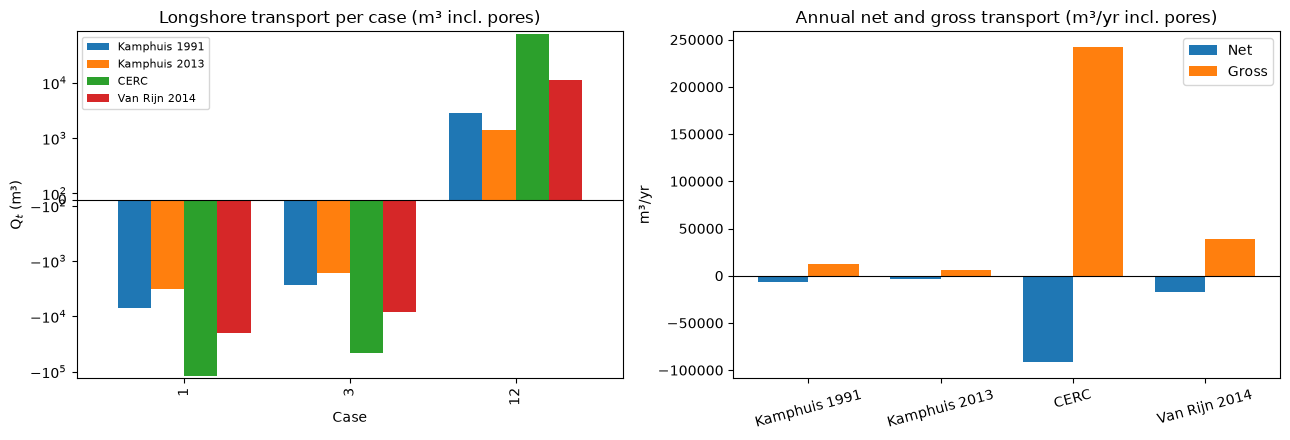

In [24]:
active = Q[cases.days.gt(0)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) per-case transport, all methods
active.plot.bar(ax=axes[0], width=0.8)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("Longshore transport per case (m³ incl. pores)")
axes[0].set_xlabel("Case"); axes[0].set_ylabel("Q$_t$ (m³)")
axes[0].set_yscale("symlog", linthresh=1e3)
axes[0].legend(fontsize=8)

# (b) annual net vs gross
x = np.arange(len(Q.columns)); w = 0.38
axes[1].bar(x - w/2, net.values,   w, label="Net")
axes[1].bar(x + w/2, gross.values, w, label="Gross")
axes[1].set_xticks(x); axes[1].set_xticklabels(Q.columns, rotation=15)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Annual net and gross transport (m³/yr incl. pores)")
axes[1].set_ylabel("m³/yr"); axes[1].legend()

plt.tight_layout()
figures["longshore_transport"] = fig
tables["transport_per_case"] = active.round(0)
tables["annual_net_gross"] = pd.DataFrame({"Net (m³/yr)": net, "Gross (m³/yr)": gross}).round(0)
plt.show()

## Save data

In [25]:
# Save figures and tables (only when SAVE = True)
import os

if SAVE:
    os.makedirs(fig_dir, exist_ok=True)
    os.makedirs(table_dir, exist_ok=True)
    for name, fig in figures.items():
        fig.savefig(f"{fig_dir}/{name}.png", dpi=300, bbox_inches="tight")
    for name, table in tables.items():
        table.to_csv(f"{table_dir}/{name}.csv", encoding="utf-8-sig")

## 10. Use with your own wave climate

Change the inputs in section 2 (global parameters and the `populated` dictionary of wave cases), then re-run the notebook from top to bottom.
The number of days of all cases must add up to 365. More cases can be added to `populated` (case numbers 1-49).

The sheet's original defaults (`Littoral.xls`) differ from the PDF run (e.g. 0 % mud, 10 % swell, tidal currents of +0.05 / −0.1 m/s,
d50 = 0.2 mm, tan β = 0.02 and 12 cases of 0.75-1.25 m waves); the PDF values were used here because the PDF is the reference output.